# Tema 3.2 · Anotación semántica

Anotar es asignar **significado** a una imagen: una etiqueta, unas cajas, una máscara.

In [ ]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy import ndimage as ndi
from skimage import data, filters, measure, morphology, segmentation, color, feature

warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.precision', 3)

## 1. Cuatro niveles de anotación

Segmentamos las monedas (Sobel + *watershed*, como en el notebook 3.1) y generamos con ello las cuatro anotaciones posibles. Fíjate en **cuántos números** hay que guardar en cada nivel: es una buena aproximación de lo que cuesta anotarlo a mano.

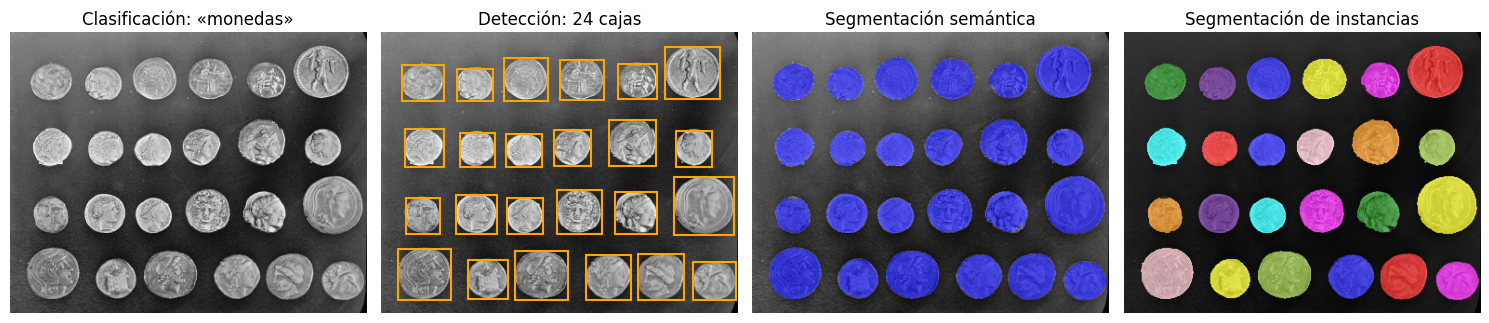

Números que hay que guardar:
  clasificación          : 1 etiqueta
  detección              : 24 objetos × (clase + 4 coordenadas) = 120
  segmentación semántica : 303×384 = 116,352 etiquetas de píxel
  instancias             : 116,352 etiquetas de píxel + identidad de 24 objetos


In [ ]:
img = data.coins()
marc = np.zeros_like(img); marc[img < 30] = 1; marc[img > 150] = 2
mask = segmentation.watershed(filters.sobel(img), marc) == 2
mask = morphology.remove_small_objects(ndi.binary_fill_holes(mask), 300)
inst = measure.label(mask)
props = measure.regionprops(inst)
cajas = [(p.bbox[1], p.bbox[0], p.bbox[3] - p.bbox[1], p.bbox[2] - p.bbox[0]) for p in props]   # (x, y, w, h)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a in ax: a.imshow(img, cmap='gray'); a.axis('off')
ax[0].set_title('Clasificación: «monedas»')
for bx, by, bw, bh in cajas:
    ax[1].add_patch(patches.Rectangle((bx, by), bw, bh, fill=False, ec='orange', lw=1.5))
ax[1].set_title(f'Detección: {len(cajas)} cajas')
ax[2].imshow(np.ma.masked_where(~mask, mask), cmap='winter', alpha=0.6); ax[2].set_title('Segmentación semántica')
ax[3].imshow(color.label2rgb(inst, bg_label=0), alpha=0.6); ax[3].set_title('Segmentación de instancias')
plt.tight_layout(); plt.show()

H, W = img.shape
print('Números que hay que guardar:')
print(f'  clasificación          : 1 etiqueta')
print(f'  detección              : {len(cajas)} objetos × (clase + 4 coordenadas) = {len(cajas) * 5}')
print(f'  segmentación semántica : {H}×{W} = {H * W:,} etiquetas de píxel')
print(f'  instancias             : {H * W:,} etiquetas de píxel + identidad de {inst.max()} objetos')

## 2. Formatos de anotación

La misma caja se guarda de forma distinta según el formato:

| Formato | Coordenadas | Unidades |
|---|---|---|
| COCO (JSON) | `[x, y, ancho, alto]` desde la esquina superior izquierda | píxeles |
| YOLO (.txt) | `clase xc yc ancho alto` desde el **centro** | normalizadas a [0, 1] |
| Pascal VOC (XML) | `xmin, ymin, xmax, ymax` | píxeles |

Escribimos las conversiones y las comprobamos con el ejemplo de las diapositivas (imagen 640×480, caja en x=100, y=120, 200×150).

In [ ]:
def coco_a_yolo(b, W, H):
    x, y, w, h = b
    return ((x + w / 2) / W, (y + h / 2) / H, w / W, h / H)

def yolo_a_coco(b, W, H):
    xc, yc, w, h = b
    return ((xc - w / 2) * W, (yc - h / 2) * H, w * W, h * H)

def coco_a_voc(b):
    x, y, w, h = b
    return (x, y, x + w, y + h)

caja = (100, 120, 200, 150)
print('COCO :', caja)
print('YOLO :', coco_a_yolo(caja, 640, 480))
print('VOC  :', coco_a_voc(caja))
assert coco_a_yolo(caja, 640, 480) == (0.3125, 0.40625, 0.3125, 0.3125)
assert np.allclose(yolo_a_coco(coco_a_yolo(caja, 640, 480), 640, 480), caja)
print('Conversiones correctas')

COCO : (100, 120, 200, 150)
YOLO : (0.3125, 0.40625, 0.3125, 0.3125)
VOC  : (100, 120, 300, 270)
Conversiones correctas


Exportamos las monedas detectadas en formato COCO (un JSON con imágenes, categorías y anotaciones) y en formato YOLO (una línea por objeto).

In [ ]:
coco = {
    'images': [{'id': 1, 'file_name': 'coins.png', 'width': W, 'height': H}],
    'categories': [{'id': 1, 'name': 'moneda'}],
    'annotations': [{'id': i + 1, 'image_id': 1, 'category_id': 1, 'bbox': [int(v) for v in b],
                     'area': int(p.area)} for i, (b, p) in enumerate(zip(cajas, props))],
}
print(json.dumps(coco['annotations'][:2], indent=1))
yolo_txt = '\n'.join('0 ' + ' '.join(f'{v:.4f}' for v in coco_a_yolo(b, W, H)) for b in cajas)
print('\ncoins.txt (YOLO), primeras líneas:')
print('\n'.join(yolo_txt.splitlines()[:3]))

[
 {
  "id": 1,
  "image_id": 1,
  "category_id": 1,
  "bbox": [
   305,
   16,
   60,
   56
  ],
  "area": 2604
 },
 {
  "id": 2,
  "image_id": 1,
  "category_id": 1,
  "bbox": [
   132,
   28,
   47,
   46
  ],
  "area": 1653
 }
]

coins.txt (YOLO), primeras líneas:
0 0.8724 0.1452 0.1562 0.1848
0 0.4049 0.1683 0.1224 0.1518
0 0.5625 0.1700 0.1250 0.1419


## 3. ¿Es fiable la anotación? κ de Cohen

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

$p_o$ es el acuerdo observado y $p_e$ el que se obtendría **por azar** si cada anotador etiquetase al azar con sus propias frecuencias. Reproducimos el ejemplo de las diapositivas: 100 imágenes, dos anotadores, clases gato/perro.

In [ ]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix

# Tabla de las diapositivas: filas = anotador A, columnas = anotador B
tabla = np.array([[40, 10],
                  [15, 35]])
A = np.repeat([0, 0, 1, 1], tabla.ravel())   # 0 = gato, 1 = perro
B = np.repeat([0, 1, 0, 1], tabla.ravel())

def kappa(a, b):
    C = confusion_matrix(a, b); n = C.sum()
    po = np.trace(C) / n
    pe = np.sum(C.sum(0) * C.sum(1)) / n ** 2
    return po, pe, (po - pe) / (1 - pe)

po, pe, k = kappa(A, B)
print(f'p_o = {po:.2f}   p_e = {pe:.2f}   κ = {k:.2f}')
print(f'sklearn: κ = {cohen_kappa_score(A, B):.2f}')

p_o = 0.75   p_e = 0.50   κ = 0.50
sklearn: κ = 0.50


### ¿Por qué no basta con el porcentaje de acuerdo?

Imagina un dataset muy desequilibrado: 95 % gatos. Un anotador perezoso dice «gato» siempre. Coincide con un anotador cuidadoso en el 95 % de los casos… pero no aporta ninguna información. κ lo detecta:

In [ ]:
rng = np.random.default_rng(0)
verdad = (rng.random(1000) < 0.05).astype(int)                 # 5 % perros
cuidadoso = np.where(rng.random(1000) < 0.97, verdad, 1 - verdad)   # acierta el 97 %
perezoso = np.zeros(1000, int)                                    # siempre «gato»

for nombre, anot in [('cuidadoso', cuidadoso), ('perezoso', perezoso)]:
    acuerdo = np.mean(anot == verdad)
    print(f'{nombre:10s}  acuerdo = {acuerdo:.1%}   κ = {cohen_kappa_score(verdad, anot):.2f}')

cuidadoso   acuerdo = 97.0%   κ = 0.73
perezoso    acuerdo = 95.5%   κ = 0.00


## 4. Anotación automática: características + clasificador

Cualquier vector de características del Tema 3.1 puede alimentar un clasificador que **anote** imágenes nuevas. Usamos los dígitos manuscritos de `scikit-learn` (1 797 imágenes 8×8) y comparamos píxeles crudos frente a HOG con tres clasificadores.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

digits = load_digits()
X_pix = digits.data
from skimage import transform
# HOG directamente sobre 8×8: sólo 2×2 celdas de 4 píxeles
X_hog8 = np.array([feature.hog(im, orientations=8, pixels_per_cell=(4, 4), cells_per_block=(1, 1)) for im in digits.images])
# HOG tras ampliar a 32×32: 4×4 celdas de 8 píxeles y bloques 2×2
X_hog = np.array([feature.hog(transform.resize(im / 16, (32, 32)), orientations=9, pixels_per_cell=(8, 8),
                              cells_per_block=(2, 2)) for im in digits.images])
y = digits.target
print('píxeles:', X_pix.shape[1], '· HOG 8×8:', X_hog8.shape[1], '· HOG 32×32:', X_hog.shape[1], 'valores')

idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.3, random_state=0, stratify=y)
clfs = {'k-NN (k=3)': KNeighborsClassifier(3),
        'Regresión logística': LogisticRegression(max_iter=2000),
        'SVM (RBF)': SVC()}
filas = []
for fnombre, X in [('píxeles', X_pix), ('HOG 8×8', X_hog8), ('HOG 32×32', X_hog)]:
    for cnombre, clf in clfs.items():
        m = make_pipeline(StandardScaler(), clf).fit(X[idx_tr], y[idx_tr])
        p = m.predict(X[idx_te])
        filas.append([fnombre, cnombre, accuracy_score(y[idx_te], p), f1_score(y[idx_te], p, average='macro')])
res = pd.DataFrame(filas, columns=['características', 'clasificador', 'exactitud', 'F1 macro'])
display(res.pivot(index='clasificador', columns='características', values='F1 macro')[['píxeles', 'HOG 8×8', 'HOG 32×32']])

píxeles: 64 · HOG 8×8: 32 · HOG 32×32: 324 valores


características,píxeles,HOG 8×8,HOG 32×32
clasificador,,,
Regresión logística,0.972,0.811,0.980
SVM (RBF),0.982,0.844,0.989
k-NN (k=3),0.979,0.751,0.989


**Lectura.** Con 8×8 píxeles, HOG sólo tiene 2×2 celdas y pierde información: queda **por debajo** de los píxeles crudos. Al ampliar la imagen a 32×32 y usar celdas de 8×8 con bloques, HOG supera a los píxeles con los tres clasificadores. Un descriptor sólo es bueno si su escala encaja con la de los objetos.

### Matriz de confusión e informe por clase

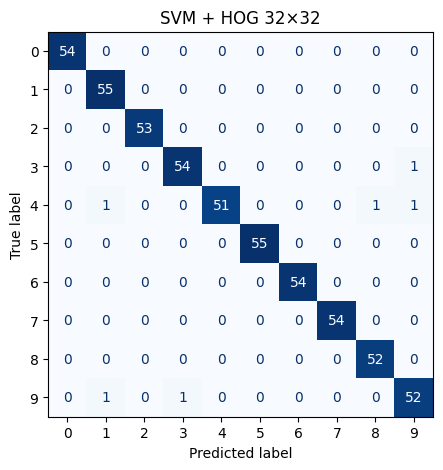

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        54
           1      0.965     1.000     0.982        55
           2      1.000     1.000     1.000        53
           3      0.982     0.982     0.982        55
           4      1.000     0.944     0.971        54
           5      1.000     1.000     1.000        55
           6      1.000     1.000     1.000        54
           7      1.000     1.000     1.000        54
           8      0.981     1.000     0.990        52
           9      0.963     0.963     0.963        54

    accuracy                          0.989       540
   macro avg      0.989     0.989     0.989       540
weighted avg      0.989     0.989     0.989       540



In [ ]:
modelo = make_pipeline(StandardScaler(), SVC()).fit(X_hog[idx_tr], y[idx_tr])
pred = modelo.predict(X_hog[idx_te])
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y[idx_te], pred, ax=ax, colorbar=False, cmap='Blues')
ax.set_title('SVM + HOG 32×32'); plt.show()
print(classification_report(y[idx_te], pred, digits=3))

### Macro frente a micro cuando las clases están desequilibradas

Quitamos el 90 % de los ejemplos de entrenamiento y prueba de los dígitos 8 y 9 y volvemos a evaluar. La exactitud y el F1 micro apenas se mueven; el F1 macro, que da el mismo peso a cada clase, revela que las clases minoritarias van peor.

In [ ]:
rng = np.random.default_rng(1)
keep = ~np.isin(y, [8, 9]) | (rng.random(len(y)) < 0.1)
tr = idx_tr[keep[idx_tr]]; te = idx_te[keep[idx_te]]
m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_pix[tr], y[tr])
p = m.predict(X_pix[te])
print(f'ejemplos de test de 8 y 9: {np.isin(y[te], [8, 9]).sum()} de {len(te)}')
print(f'exactitud = {accuracy_score(y[te], p):.3f}')
print(f'F1 micro  = {f1_score(y[te], p, average="micro"):.3f}')
print(f'F1 macro  = {f1_score(y[te], p, average="macro"):.3f}')
print('F1 por clase:', np.round(f1_score(y[te], p, average=None), 2))

ejemplos de test de 8 y 9: 13 de 447
exactitud = 0.969
F1 micro  = 0.969
F1 macro  = 0.842
F1 por clase: [1.   0.96 0.99 0.96 0.99 0.97 0.99 0.98 0.   0.57]


## 5. Multietiqueta: una sigmoide por clase y un umbral

En multietiqueta cada imagen puede tener varias etiquetas ("playa", "persona", "atardecer"). Se entrena un clasificador binario por etiqueta y se asignan todas las que superan un **umbral**. Usamos datos sintéticos para ver cómo el umbral cambia el resultado.

Probabilidades de la 1.ª imagen: {'playa': 0.2, 'persona': 0.02, 'atardecer': 0.4, 'perro': 0.5, 'coche': 1.0}
Etiquetas reales               : ['coche']


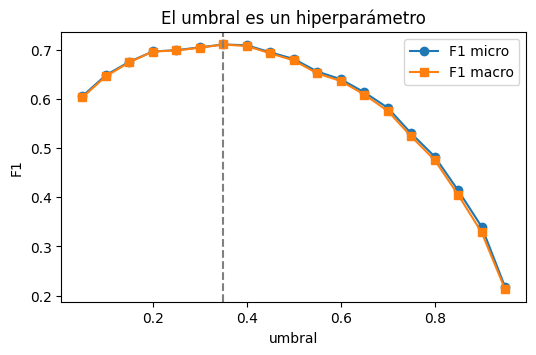

Mejor umbral (F1 micro): 0.35


In [ ]:
from sklearn.datasets import make_multilabel_classification
from sklearn.multiclass import OneVsRestClassifier

etiquetas = ['playa', 'persona', 'atardecer', 'perro', 'coche']
X, Y = make_multilabel_classification(n_samples=1500, n_features=30, n_classes=5, n_labels=2, random_state=0)
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=0.3, random_state=0)
ovr = OneVsRestClassifier(LogisticRegression(max_iter=2000)).fit(Xtr, Ytr)
prob = ovr.predict_proba(Xte)                         # una probabilidad independiente por etiqueta
print('Probabilidades de la 1.ª imagen:', {e: round(float(v), 2) for e, v in zip(etiquetas, prob[0])})
print('Etiquetas reales               :', [e for e, v in zip(etiquetas, Yte[0]) if v])

umbrales = np.linspace(0.05, 0.95, 19)
f1mi = [f1_score(Yte, prob >= t, average='micro') for t in umbrales]
f1ma = [f1_score(Yte, prob >= t, average='macro', zero_division=0) for t in umbrales]
plt.figure(figsize=(6, 3.5))
plt.plot(umbrales, f1mi, 'o-', label='F1 micro'); plt.plot(umbrales, f1ma, 's-', label='F1 macro')
plt.axvline(umbrales[np.argmax(f1mi)], color='gray', ls='--')
plt.xlabel('umbral'); plt.ylabel('F1'); plt.legend(); plt.title('El umbral es un hiperparámetro'); plt.show()
print(f'Mejor umbral (F1 micro): {umbrales[np.argmax(f1mi)]:.2f}')

## 6. Detección: IoU, NMS y precisión media

### 6.1 IoU

$$\mathrm{IoU} = \frac{|A \cap B|}{|A \cup B|}$$

Comprobamos con el ejemplo de las diapositivas: dos cajas de 4×3 que se solapan en un cuadrado de 2×2.

In [ ]:
def iou(a, b):
    """Cajas en formato COCO (x, y, w, h)."""
    ax2, ay2, bx2, by2 = a[0] + a[2], a[1] + a[3], b[0] + b[2], b[1] + b[3]
    iw = max(0, min(ax2, bx2) - max(a[0], b[0]))
    ih = max(0, min(ay2, by2) - max(a[1], b[1]))
    inter = iw * ih
    return inter / (a[2] * a[3] + b[2] * b[3] - inter)

print('IoU ejemplo de las diapositivas:', iou((1, 1, 4, 3), (3, 2, 4, 3)))
print('IoU de una caja consigo misma  :', iou(caja, caja))
print('IoU de cajas disjuntas         :', iou((0, 0, 1, 1), (5, 5, 1, 1)))

IoU ejemplo de las diapositivas: 0.2
IoU de una caja consigo misma  : 1.0
IoU de cajas disjuntas         : 0.0


### 6.2 Un detector simulado y NMS

Simulamos un detector imperfecto sobre las monedas: para cada moneda produce **tres cajas ruidosas** con distinta confianza, y además añade **8 falsas alarmas** aleatorias. NMS elimina los duplicados.

Antes de NMS: 80 detecciones · después: 34 · monedas reales: 24


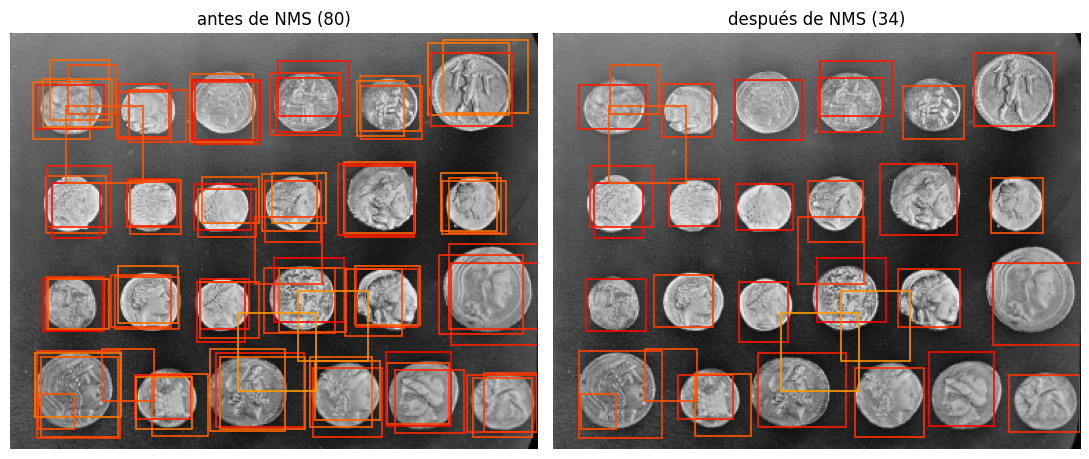

In [ ]:
rng = np.random.default_rng(3)
dets = []
for bx, by, bw, bh in cajas:
    for _ in range(3):
        j = rng.normal(0, 0.08, 4) * [bw, bh, bw, bh]
        dets.append((bx + j[0], by + j[1], bw + j[2], bh + j[3], rng.uniform(0.5, 1.0)))
for _ in range(8):
    s = rng.uniform(25, 60)
    dets.append((rng.uniform(0, W - s), rng.uniform(0, H - s), s, s, rng.uniform(0.3, 0.8)))
dets = np.array(dets)

def nms(dets, umbral=0.5):
    orden = np.argsort(-dets[:, 4]); quedan = []
    while len(orden):
        i = orden[0]; quedan.append(i)
        orden = np.array([j for j in orden[1:] if iou(dets[i, :4], dets[j, :4]) <= umbral], dtype=int)
    return dets[quedan]

tras_nms = nms(dets)
print(f'Antes de NMS: {len(dets)} detecciones · después: {len(tras_nms)} · monedas reales: {len(cajas)}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, D, t in [(ax[0], dets, 'antes de NMS'), (ax[1], tras_nms, 'después de NMS')]:
    a.imshow(img, cmap='gray'); a.axis('off'); a.set_title(f'{t} ({len(D)})')
    for bx, by, bw, bh, sc in D:
        a.add_patch(patches.Rectangle((bx, by), bw, bh, fill=False, ec=plt.cm.autumn(1 - sc), lw=1.2))
plt.tight_layout(); plt.show()

### 6.3 Emparejar con la verdad y calcular la precisión media (AP)

Ordenamos las detecciones por confianza; cada una es **verdadero positivo** si tiene IoU ≥ 0,5 con una moneda aún no emparejada. Con la secuencia de aciertos construimos la curva precisión-recall y su área: la **AP** (en detección, mAP es la media de AP sobre las clases).

sin NMS: TP=24  FP=56  FN=0  precisión=0.30  recall=1.00  AP@0,5=0.806
con NMS: TP=24  FP=10  FN=0  precisión=0.71  recall=1.00  AP@0,5=0.930


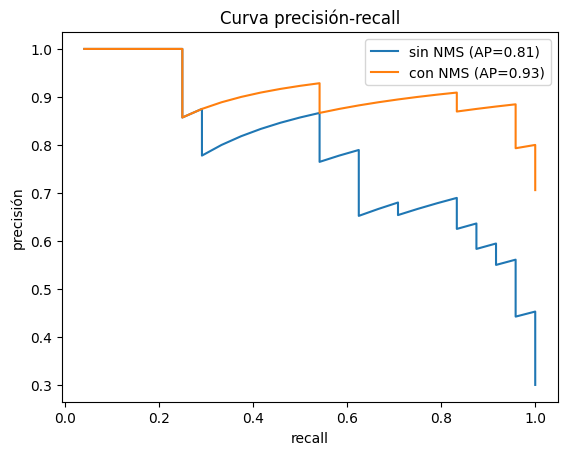

In [ ]:
def evaluar(D, gt, umbral=0.5):
    D = D[np.argsort(-D[:, 4])]
    usado = np.zeros(len(gt), bool); tp = []
    for d in D:
        ious = np.array([iou(d[:4], g) for g in gt])
        ious[usado] = 0
        k = ious.argmax()
        if ious[k] >= umbral:
            usado[k] = True; tp.append(1)
        else:
            tp.append(0)
    tp = np.array(tp); ctp = np.cumsum(tp)
    precision = ctp / np.arange(1, len(tp) + 1)
    recall = ctp / len(gt)
    # AP: área bajo la curva P-R con precisión interpolada (estilo VOC, todos los puntos)
    p_interp = np.maximum.accumulate(precision[::-1])[::-1]
    ap = np.sum(np.diff(np.concatenate([[0], recall])) * p_interp)
    return precision, recall, ap, tp.sum()

for nombre, D in [('sin NMS', dets), ('con NMS', tras_nms)]:
    P, R, ap, ntp = evaluar(D, cajas)
    print(f'{nombre}: TP={ntp}  FP={len(D) - ntp}  FN={len(cajas) - ntp}  '
          f'precisión={ntp / len(D):.2f}  recall={ntp / len(cajas):.2f}  AP@0,5={ap:.3f}')
    plt.plot(R, P, label=f'{nombre} (AP={ap:.2f})')
plt.xlabel('recall'); plt.ylabel('precisión'); plt.legend(); plt.title('Curva precisión-recall'); plt.show()

## 7. [Colab] Humanos contra CLIP

Vamos a **anotar nosotros** 20 imágenes de CIFAR-10 y comparar nuestra anotación con la verdad y con CLIP *zero-shot*. Ejecuta la celda, mira las imágenes y escribe tus etiquetas en la lista `mis_etiquetas` (usa los nombres de la lista `clases`).

100%|██████████| 170M/170M [27:32<00:00, 103kB/s]


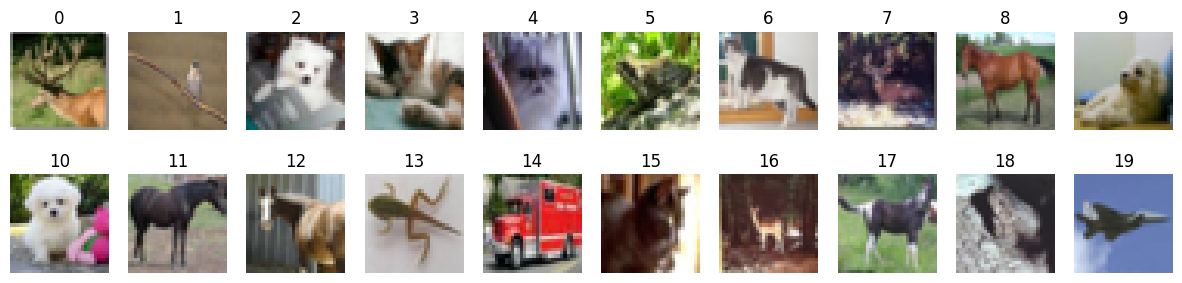

Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# [Colab] Datos y CLIP
import torch
from torchvision import datasets
from transformers import CLIPModel, CLIPProcessor

device = 'cuda' if torch.cuda.is_available() else 'cpu'
test = datasets.CIFAR10('data', train=False, download=True)
clases = test.classes
idx = np.random.default_rng(42).choice(len(test), 20, replace=False)
ims = [test[i][0] for i in idx]; verdad20 = np.array([test[i][1] for i in idx])

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for k, (a, im) in enumerate(zip(axes.ravel(), ims)):
    a.imshow(im); a.set_title(str(k)); a.axis('off')
plt.show()
print('Clases:', clases)

In [ ]:
# [Colab] Escribe aquí tus 20 etiquetas, en el orden de las imágenes (0 a 19)
mis_etiquetas = ['cat'] * 20      # ← cámbialas

In [ ]:
# [Colab] CLIP zero-shot y comparación
clip = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval()
proc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')

def _tensor(o):
    if torch.is_tensor(o):
        return o
    for k in ('image_embeds', 'text_embeds', 'pooler_output'):
        if getattr(o, k, None) is not None:
            return getattr(o, k)
    return o[0]

with torch.no_grad():
    fi = _tensor(clip.get_image_features(**proc(images=ims, return_tensors='pt').to(device)))
    ft = _tensor(clip.get_text_features(**proc(text=[f'a photo of a {c}.' for c in clases],
                                                return_tensors='pt', padding=True).to(device)))
fi = torch.nn.functional.normalize(fi, dim=1); ft = torch.nn.functional.normalize(ft, dim=1)
pred_clip = (fi @ ft.T).argmax(1).cpu().numpy()
yo = np.array([clases.index(e) for e in mis_etiquetas])

print(f'Yo   : exactitud = {np.mean(yo == verdad20):.2f}   κ con la verdad = {cohen_kappa_score(verdad20, yo):.2f}')
print(f'CLIP : exactitud = {np.mean(pred_clip == verdad20):.2f}   κ con la verdad = {cohen_kappa_score(verdad20, pred_clip):.2f}')
print(f'Acuerdo yo–CLIP: κ = {cohen_kappa_score(yo, pred_clip):.2f}')
for k in np.where((yo != verdad20) | (pred_clip != verdad20))[0]:
    print(f'  imagen {k:2d}: verdad={clases[verdad20[k]]:10s} yo={clases[yo[k]]:10s} CLIP={clases[pred_clip[k]]}')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Yo   : exactitud = 0.20   κ con la verdad = 0.00
CLIP : exactitud = 0.90   κ con la verdad = 0.88
Acuerdo yo–CLIP: κ = 0.00
  imagen  0: verdad=deer       yo=cat        CLIP=deer
  imagen  1: verdad=bird       yo=cat        CLIP=bird
  imagen  2: verdad=dog        yo=cat        CLIP=dog
  imagen  5: verdad=frog       yo=cat        CLIP=frog
  imagen  7: verdad=deer       yo=cat        CLIP=deer
  imagen  8: verdad=horse      yo=cat        CLIP=horse
  imagen  9: verdad=dog        yo=cat        CLIP=dog
  imagen 10: verdad=dog        yo=cat        CLIP=dog
  imagen 11: verdad=horse      yo=cat        CLIP=horse
  imagen 12: verdad=horse      yo=cat        CLIP=horse
  imagen 13: verdad=frog       yo=cat        CLIP=frog
  imagen 14: verdad=truck      yo=cat        CLIP=truck
  imagen 16: verdad=deer       yo=cat        CLIP=cat
  imagen 17: verdad=horse      yo=cat        CLIP=horse
  imagen 18: verdad=frog       yo=cat        CLIP=bird
  imagen 19: verdad=airplane   yo=cat        CLIP=

## 8. Ejercicios

1. Calcula κ entre los dos miembros de la pareja con vuestras 20 etiquetas de la sección 7. ¿Qué imágenes generan desacuerdo?
2. En la sección 4, sustituye HOG por el histograma LBP del notebook 3.1. ¿Qué clasificador funciona mejor ahora?
3. En la sección 6, cambia el umbral de NMS a 0,3 y a 0,7. ¿Qué pasa con la precisión, el recall y la AP? ¿Y si exiges IoU ≥ 0,75 para contar un acierto?
4. Construye un conjunto multietiqueta con tus propias imágenes (5 etiquetas, 30 imágenes) usando CLIP con una frase por etiqueta y un umbral sobre la similitud. ¿Qué umbral elegirías y por qué?